In [1]:
import sys
from pathlib import Path
import importlib

ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir() and (candidate / "project.ipynb").is_file():
        ROOT = candidate
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pyspark.sql import SparkSession
from src.dataOI import DataOI

SEED = 42
# True: rebuild the encoded split from the raw CSV; False: load its local cache.
# The flag controls input preparation, not model training.
REBUILD = True

# `spark.driver.memory` is read only when the JVM starts. Restart the kernel after changing it.
spark = SparkSession.builder \
                            .master("local[*]")\
                            .appName("DrugReviewClassification")\
                            .config("spark.driver.memory","6g")\
                            .getOrCreate()
spark_context = spark.sparkContext
spark_context.setLogLevel("ERROR")
data_oi = DataOI()


In [2]:
df_raw = data_oi.load_raw_data()
df_raw.show(truncate= 80)
print("rows:", df_raw.count())

+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                          drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|                         Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|                        Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                            Lybrel|               Birth Cont

### Exploratory Data Analysis (EDA)
Begin by trying to comprehend what your dataset conveys.
- What type of data are you currently exploring?
- What is the granularity of the data?
- What does the distribution of the data look like? Are there any outliers? Are there any missing or invalid entries?
- Is there any correlation between the variables you are interested in exploring?
- How would you cleanly and accurately visualize the relationship among variables?

#### Data types and research objective

The UCI Drug Review dataset records patients' comments on specific drugs, the associated conditions or indications, and overall satisfaction ratings.
It contains **mixed data types: primarily unstructured text, together with categorical, numerical, and date fields**. This project predicts the original `rating` through **ten-class classification on a 1–10 scale**.

| Field | Spark type | Meaning and analytical use |
|---|---|---|
| `uniqueID` | integer | Review record identifier, used to check uniqueness; it is not a patient identifier. |
| `drugName` | string | Drug name, a categorical field; the number of names does not equal the number of drug entities after name consolidation. |
| `condition` | string | Condition or indication, examined for missing values, category counts, and field contamination. |
| `review` | string | Patient comment and the main text input; it may contain HTML entities and surrounding quotation marks. |
| `rating` | integer | Ordinal satisfaction label on a 1–10 scale. |
| `date` | date | Review publication date, used in temporal correlation analysis. |
| `usefulCount` | integer | Number of helpful votes, which accumulate after publication. |


In [3]:
from src.eda import EDA

eda_raw = EDA(df_raw)
eda_raw.dataframe_overview()

DataFrame overview
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|               Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|              Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                  Lybrel|               Birth Control|"I used to take another oral contrace

**Interpreting the schema.** The dataset contains three string fields, three integer fields, and one date field. In the schema, `nullable = true` means that a field permits null values; it does not mean that every field actually contains missing values.
The ellipses produced by `.show(truncate=80)` are display limits and do not indicate that the original comments have been shortened.


In [5]:
eda_raw.granularity()

DataFrame granularity
Total row count: 161297
`drugName`:
+-------------------------------+
|                       drugName|
+-------------------------------+
|                         Dulera|
|                         Prozac|
|                          Arava|
|                         Maxalt|
|                     Tazarotene|
|                      Primidone|
|Acetaminophen / diphenhydramine|
|                       Treximet|
|                         Avapro|
|                        Prograf|
|                      Auranofin|
|               Spiriva Respimat|
|              Parafon Forte DSC|
|                       Dupixent|
|                      Nebivolol|
|                         Nexium|
|                         Ceftin|
|                        Enjuvia|
|                    Benicar HCT|
|                    Penciclovir|
+-------------------------------+
only showing top 20 rows
`drugName` count: 3436
`condition`:
+-------------------------------------------+
|                  

#### Data granularity and duplicate records

The file contains **161,297 records**, with **one drug review per row**, together with its associated drug name, indication, rating, publication date, and helpful-vote count.
Although `uniqueID` is unique within the file, there is no field that identifies individual patients. The record count therefore cannot be interpreted as the number of distinct patients.

- There are **3,436 distinct drug-name values**, before name consolidation.
- The output reports **885 distinct `condition` values**. The current `select("condition").distinct().count()` includes null as one distinct value, leaving **884 non-null raw names**.
  These include webpage messages and incomplete names, so they cannot be described as 884 confirmed disease categories.
- Exact matching of the original review text identifies **48,635 groups of duplicate reviews**, including **72 groups** with different ratings.


Data Distribution
`rating` is in the range [1, 10]
`rating` record count:
+------+-----+
|rating|count|
+------+-----+
|     1|21619|
|     2| 6931|
|     3| 6513|
|     4| 5012|
|     5| 8013|
|     6| 6343|
|     7| 9456|
|     8|18890|
|     9|27531|
|    10|50989|
+------+-----+

+------------------+-----------------+-------------------+
|          variance|           stddev|           skewness|
+------------------+-----------------+-------------------+
|10.708138452208162|3.272329209020413|-0.7986194576447084|
+------------------+-----------------+-------------------+



D:\python\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 16.1.0.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


`usefulCount`:
+-------+-----------+
|summary|usefulCount|
+-------+-----------+
|    min|          0|
|    25%|          6|
|    50%|         16|
|    75%|         36|
|    max|       1291|
+-------+-----------+

The highest `usefulCount` record:
+--------+----------+----------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|  drugName| condition|                                                                          review|rating|      date|usefulCount|
+--------+----------+----------+--------------------------------------------------------------------------------+------+----------+-----------+
|   96616|Sertraline|Depression|"I remember reading people&#039;s opinions, online, of the drug before I took...|    10|2008-07-31|       1291|
|  119152|    Zoloft|Depression|"I remember reading people&#039;s opinions, online, of the drug before I took...|    10|2008-07-31|       1291|
+--------+----------+----------+

D:\python\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 16.1.0.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


`review` length:
+-------+-------------+
|summary|review_length|
+-------+-------------+
|    min|            3|
|    25%|          262|
|    50%|          455|
|    75%|          690|
|    max|        10745|
+-------+-------------+

The longest `review` record:
+--------+-----------+---------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|   drugName|condition|                                                                          review|rating|      date|usefulCount|
+--------+-----------+---------+--------------------------------------------------------------------------------+------+----------+-----------+
|  121004|Venlafaxine| Migraine|"Two and a half months ago I was prescribed Venlafaxine to help prevent chron...|     2|2017-06-18|          9|
+--------+-----------+---------+--------------------------------------------------------------------------------+------+----------+-----------+

The abnormal sho

D:\python\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 16.1.0.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


`uniqueID` has 0 null records
`drugName` has 0 null records
`condition` has 899 null records
`review` has 0 null records
`rating` has 0 null records
`date` has 0 null records
`usefulCount` has 0 null records


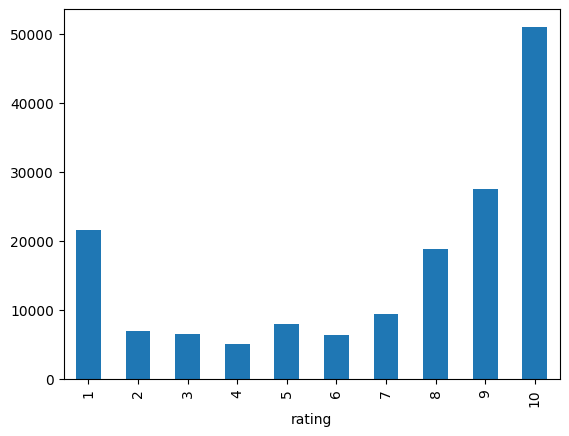

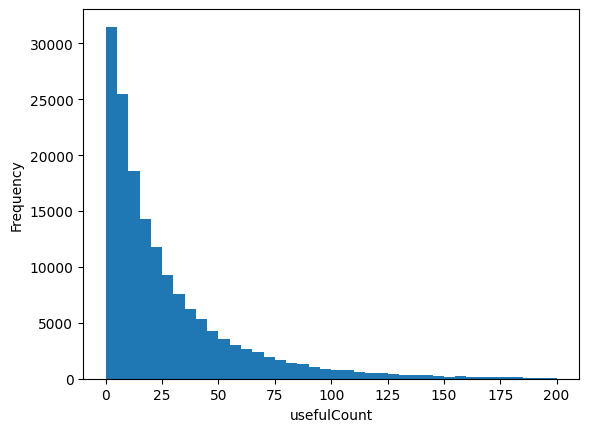

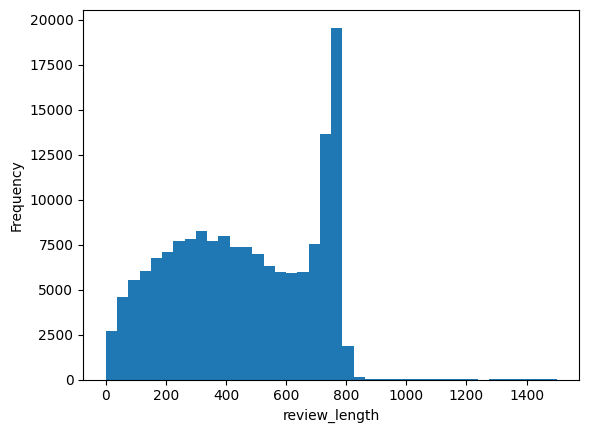

In [6]:
eda_raw.distribution_inspect()

#### Distributions and extreme examples

**Ratings.** The existing checks confirm that ratings fall within 1–10. A rating of 10 accounts for **50,989 records, or 31.61%**;
ratings of 8–10 together account for **97,410 records, or 60.39%**.
There are also 21,619 records with a rating of 1, while the least frequent class, rating 4, has only 5,012 records. The largest-to-smallest class frequency ratio is approximately **10.17**.
The classes are imbalanced, so overall accuracy alone cannot establish good performance across all classes. Subsequent experiments can compare weighting strategies and examine macro-averaged and per-class metrics. The skewness of approximately −0.799 is consistent with the concentration of higher ratings.

**Helpful votes.** The minimum is 0, the quartiles are 6, 16, and 36, and the maximum is 1,291. A skewness of approximately **4.667** indicates a pronounced right tail.
High vote counts may be valid feedback and should not automatically be treated as errors. `log1p` is a possible transformation for later experiments; its effect requires validation.

**Review length.** Length is measured in characters in the original string, including HTML entities and surrounding quotation marks. It is not a word count or a model token count.
The median is **455** characters, the middle 50% lie approximately between **262–690**, the minimum is **3**, and the maximum is **10,745**. Skewness is approximately **1.189**.
The shortest examples, such as `"I"`, `"G"`, and `"-"`, contain only a single character after removing the surrounding quotation marks and provide little information. Very long comments also require attention to model input-length limits.

**Histogram ranges.** The existing helpful-vote histogram displays only 0–200, while the review-length histogram displays only 0–1,500 characters.
Supplementary CSV checks found **874 records (0.54%)** and **122 records (0.076%)**, respectively, above these limits.
The plots therefore do not show the complete tails. These records remain in the original data and in statistics such as the maximum; they have not been removed.


#### Missing and invalid entries

In the existing output, only `condition` contains null values: **899 records, or approximately 0.56%**. The other six fields have 0 null values.
To cover issues that null checks cannot detect, all 161,297 rows in the same raw CSV were independently checked:

| Check | Result | Definition |
|---|---|---|
| Non-empty fields containing only whitespace | 0 records | Checked separately from missing source values. |
| Ratings that cannot be parsed as integers or fall outside 1–10 | 0 records | Checked directly from raw strings so that type conversion does not conceal problems. |
| Helpful-vote counts that cannot be parsed as integers or are negative | 0 records | Valid high counts are not automatically classified as errors. |
| Dates that cannot be parsed using `d-MMM-yy` | 0 records | Checked against the original date strings. |
| Dates later than 2026-11-02 | 0 records | Evaluated against an explicit analysis date. |
| Webpage helpful-vote messages in `condition` | 899 records, approximately 0.56% | Identified using `</span> users found this comment helpful`, which is not a condition name. |

Existing examples also contain HTML entities such as `&#039;` and category values requiring verification, such as `Panic Disorde`, `Stomach Ulce`, and `min)`.
These findings support subsequent HTML decoding, name verification, and text normalization. They do not establish that every name and the meaning of every comment have been verified.
**EDA identifies and explains these issues; deletion and replacement rules, together with changes in record counts, are documented in the Data Cleaning section.**


In [6]:
eda_raw.correlation()

Data Field Correlation
+------------------+--------------------+-------------------+
|rating_usefulCount|         rating_date|   usefulCount_date|
+------------------+--------------------+-------------------+
|0.2341853750636649|-0.19623579544730904|-0.2690699925232411|
+------------------+--------------------+-------------------+



#### Interpreting correlations

The current method examines ratings, helpful-vote counts, and dates expressed numerically. Dates are converted to days since 1970-01-01, so larger values represent later dates.
Pearson's r ranges from −1 to 1. Its sign indicates the direction of a linear relationship, while its absolute value indicates its strength.

| Variable pair | Pearson r | Interpretation |
|---|---:|---|
| Rating—helpful votes | 0.234 | A weak positive linear relationship: higher-rated comments may receive more votes overall, but the relationship is far from one-to-one. |
| Rating—date | -0.196 | A weak negative linear relationship: later comments are associated with slightly lower ratings overall. This does not establish that drug effectiveness declines over time. |
| Helpful votes—date | -0.269 | A weak negative linear relationship: earlier comments may have more votes overall. A longer period for accumulating votes is a possible explanation that requires validation. |

All three coefficients have absolute values below 0.3 and describe only overall linear relationships. A small coefficient does not establish the absence of nonlinear relationships or predictive value.
Ratings are ordinal and discrete, vote counts have a long tail, and the relationships may also reflect differences in drugs, conditions, and time.
Arbitrary numerical codes for drug or condition categories should not be treated as continuous variables in correlation analysis. These observational relationships do not establish causation.


#### Visualizing relationships

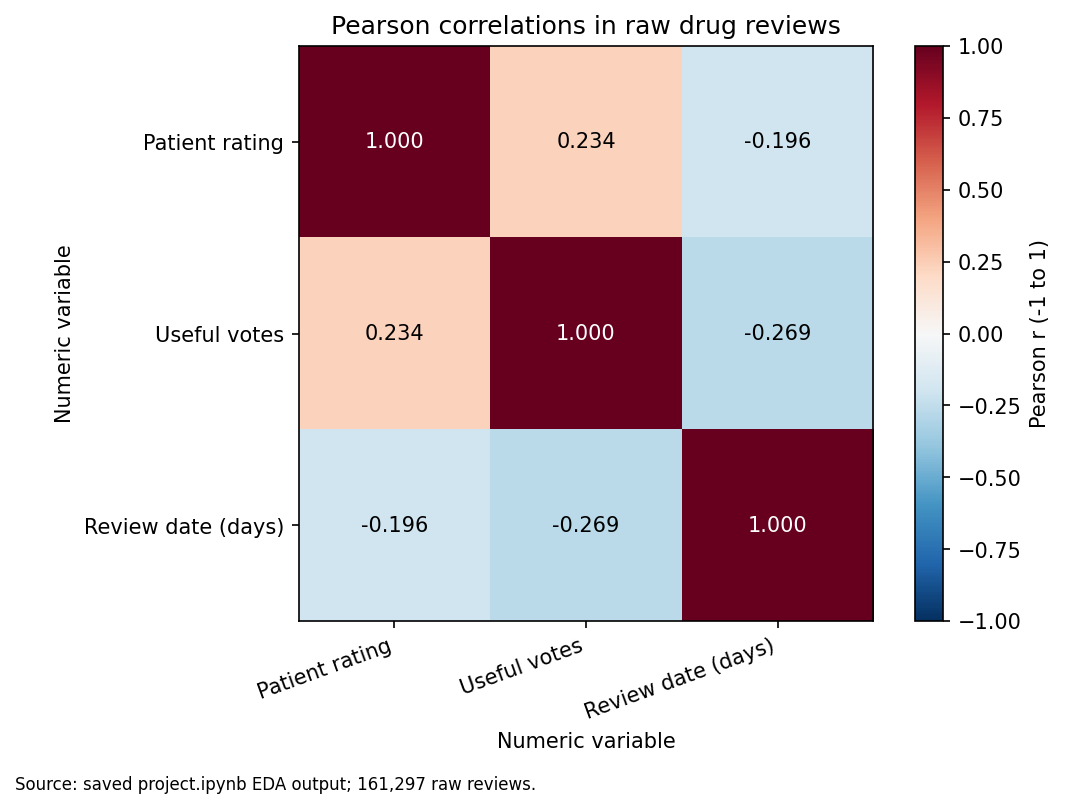

The heatmap uses the **three saved coefficients** from the current `eda_raw.correlation()` output, with a common color scale from −1 to 1.
Red represents positive correlation and blue represents negative correlation. Values are shown to three decimal places, and diagonal entries represent each variable's correlation with itself.
The heatmap complements the existing univariate distribution plots; the pale off-diagonal colors indicate that the overall linear relationships are weak.


#### EDA summary and next steps

This section establishes the data types and review-record granularity. It identifies class imbalance, missing and contaminated condition values, duplicate comments with some conflicting ratings, and long tails in helpful-vote counts and review lengths.
The numerical variables exhibit weak linear correlations. These findings inform subsequent deduplication, field correction, text normalization, class-imbalance handling, and clarification of input availability.


### Data Cleaning
A crucial step in the data preprocessing pipeline, aimed at improving the quality and accuracy of the dataset before analysis.
- Identifying Missing Values
- Handling Outliers
- Correcting Invalid Entries
- Removing Duplicates
- Standardizing Data: Ensure consistency in data representation.
- Transforming Variables: Apply necessary transformations to variables to enhance their interpretability or suitability for analysis.

In [ ]:
from src.cleaning import data_cleaning

if REBUILD:
    print("Before data cleaning:")
    df_raw.show(10,truncate=80)
    df_cleaned = data_cleaning(df_raw)
    df_cleaned.cache().count()
    print("After data cleaning:")
    df_cleaned.show(10,truncate=80)
    print("Cleaned data overview:")
    eda_cleaned = EDA(df_cleaned)
    eda_cleaned.dataframe_overview()
    eda_cleaned.granularity()
    eda_cleaned.distribution_inspect()


In [ ]:
import src.text_features
importlib.reload(src.text_features)
from src.text_features import text_feature_engineering, baseline_text_feature_engineering

df_baseline_engineered = baseline_text_feature_engineering(df_cleaned)
df_baseline_engineered.cache().count()

if REBUILD:
    print("Before text feature engineering:")
    df_cleaned.show(10,truncate = 80)
    df_engineered = text_feature_engineering(df_cleaned,True)
    df_engineered.cache().count()
    print("After text feature engineering:")
    df_engineered.show(10,truncate = 80)


In [ ]:
from src.encoder import encoder
from src.split import split_and_weight

df_baseline_train, df_baseline_test = split_and_weight(df_baseline_engineered,SEED)
df_baseline_train,df_baseline_test = encoder(df_baseline_train,df_baseline_test)

if REBUILD:
    df_train, df_test = split_and_weight(df_engineered, SEED)
    df_train, df_test = encoder(df_train, df_test)
    data_oi.save_split_data(df_train,df_test)
else:
    df_train, df_test = data_oi.load_split_data()

In [ ]:
from src.embeddings import EmbeddingModel
# Embedding Baseline Model (TFIDF without text feature engineering)

embedding_baseline_model = EmbeddingModel(df_baseline_train,df_baseline_test)
baseline_name = "baseline"
print("Embedding Baseline Model `baseline` Training")
embedding_baseline_model.tfidf_train(baseline_name)
print("Embedding Baseline Model `baseline` Running")
train_embedding_baseline, test_embedding_baseline = embedding_baseline_model.tfidf_predict(baseline_name)

In [ ]:
from src.embeddings import EmbeddingModel

# Fit registered embeddings before prediction; downstream models read `embedding`.
embedding_model = EmbeddingModel(df_train,df_test)

for name, train_function in EmbeddingModel.train_registry.items():
    print(f"Embedding Model `{name}` Training")
    train_function(embedding_model)

In [ ]:
train_embedding_dict = {}
test_embedding_dict = {}

for name, predict_function in EmbeddingModel.predict_registry.items():
    print(f"Embedding Model `{name}` Running")
    train_embedding_dict[name], test_embedding_dict[name] = predict_function(embedding_model)
    data_oi.save_embedding_data(name,train_embedding_dict[name],test_embedding_dict[name])

In [ ]:
# Analytics Baseline Model (Logistic Regression Model without weight col)

from src.analytics import AnalyticsModel
analytics_baseline_model = AnalyticsModel(train_embedding_baseline,test_embedding_baseline)

print("Analytics Baseline Model `lr` Training")
analytics_baseline_model.lr_train(baseline_name)
print("Analytics Baseline Model `lr` Running")
train_analytics_baseline, test_analytics_baseline = analytics_baseline_model.lr_predict(baseline_name)

In [ ]:
from src.analytics import AnalyticsModel

train_embedding_dict, test_embedding_dict = data_oi.load_embedding_data()

analytics_models = {}
for embedding_name in train_embedding_dict.keys():
    analytics_models[embedding_name] = AnalyticsModel(
        train_embedding_dict[embedding_name],
        test_embedding_dict[embedding_name]
    )
    for name, train_function in AnalyticsModel.train_registry.items():
        print(f"Embedding Model `{embedding_name}` Analytics Model `{name}` Training")
        train_function(analytics_models[embedding_name], embedding_name)

In [ ]:
train_pred_dict = {}
test_pred_dict = {}
for embedding_name in train_embedding_dict.keys():
    for name, predict_function in AnalyticsModel.predict_registry.items():
        print(f"Embedding Model `{embedding_name}` Analytics Model `{name}` Running")
        # Format: `{analytics}__{embedding}`. Either name may contain a single underscore.
        model_name = f"{name}__{embedding_name}"
        train_pred_dict[model_name], test_pred_dict[model_name] = predict_function(
            analytics_models[embedding_name],
            embedding_name
        )
        data_oi.save_prediction_data(
            model_name,
            train_pred_dict[model_name],
            test_pred_dict[model_name]
        )


In [ ]:
from src.evaluation import Scorer

train_pred_dict, test_pred_dict = data_oi.load_prediction_data()

scorer_train = Scorer(train_pred_dict)
scorer_train.add_model("baseline","lr",train_analytics_baseline)
print("Training Data:")
scorer_train.show_metrics(truncate = 80)

scorer_test = Scorer(test_pred_dict)
scorer_test.add_model("baseline","lr",test_analytics_baseline)
print("Tesing Data:")
scorer_test.show_metrics(truncate = 80)
